# Confianza del sistema y evaluación con canales al azar

El objetivo de este notebook es decidir **cuándo creerle al sistema** y medir cómo funciona con cualquier paciente. No entrena nada: usa las probabilidades del meta-modelo que dejó `1_entrenamiento.ipynb`.

- **Canales al azar:** en la práctica cada noche llega con una combinación distinta de canales. Se evalúa el test sorteando una combinación por noche.
- **Confianza:** la confianza de una época es la probabilidad de la clase elegida. Si es menor que un umbral, la época se marca **revisar** y el técnico recibe la 1.ª y la 2.ª opción. El umbral y el aviso por noche se eligen con la CV, antes de mirar el test, y se guardan en `modelo/sistema.json`.

El notebook se organiza así:

1. **Librerías**
2. **Rutas y parámetros**
3. **Predicciones**
4. **Test con canales al azar por noche**
5. **Confianza:** umbral y aviso por noche, elegidos con la CV.
6. **Calibración**
7. **Test con el umbral**
8. **Así entrega el sistema una noche**
9. **Guardar en `sistema.json`**
10. **Conclusiones**

## 1. Librerías

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 2. Rutas y parámetros

Las reglas para elegir el umbral y el aviso quedan fijas aquí, antes de ver ningún resultado:
- **umbral:** el menor de 0.50, 0.55, …, 0.95 con el que las épocas que el sistema entrega sin revisión aciertan al menos el 90 % en la CV, con las 12 combinaciones juntas;
- **aviso por noche:** si la fracción de la noche a revisar supera el percentil 90 de las noches de la CV.

In [2]:
# Raíz del repositorio: la carpeta que tiene particiones.json
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "particiones.json").exists())
PROCESADOS = RAIZ / "data" / "procesados"
SISTEMA = RAIZ / "modelo" / "sistema.json"

SEED = 42
N_BOOT = 2000
ESTADIOS = ["W", "N1", "N2", "N3", "REM"]
K = len(ESTADIOS)

UMBRALES = np.round(np.arange(0.50, 0.951, 0.05), 2)
ACIERTO_MINIMO = 0.90
PERCENTIL_AVISO = 0.90

particion = json.loads((RAIZ / "particiones.json").read_text())
CONFIGS = list(particion["combinaciones"])

## 3. Predicciones

Leemos las probabilidades del meta-modelo: fuera de fold en la CV (62 sujetos) y del modelo final en el test (16 sujetos). Para comparar, también las de A y B en el test.

In [3]:
# Función para leer las predicciones del meta-modelo
def load_meta():
    """'oof'/'test' -> combinación -> noche -> (y, probabilidades)"""
    z = np.load(PROCESADOS / "meta_modelo" / "predicciones.npz")
    out = {"oof": {}, "test": {}}
    for k in z.files:
        key, c, n, kind = k.split("__")
        if kind == "y":
            out[key].setdefault(c, {})[n] = (z[k], z[f"{key}__{c}__{n}__pred"])
    return out


META = load_meta()
print(f"meta-modelo: {len(META['oof']['fpz'])} noches de CV y {len(META['test']['fpz'])} de test, con 12 combinaciones")

meta-modelo: 121 noches de CV y 32 de test, con 12 combinaciones


In [4]:
# Predicciones de A y B en el test
z = np.load(PROCESADOS / "modelo_a_xgboost_100_features" / "folds" / "final.npz")
A = {c: {} for c in CONFIGS}
for k in z.files:
    c, n, kind = k.split("__")
    if kind == "y":
        A[c][n] = (z[k], z[f"{c}__{n}__pred"])

z = np.load(PROCESADOS / "modelo_b_red" / "predicciones" / "final.npz")
B = {c: {} for c in CONFIGS}
for k in z.files:
    c, n = k.split("__")
    if c in B:
        B[c][n] = (z[f"y__{n}"], z[k])

TEST = {"XGBoost (A)": A, "Red (B)": B, "Meta-modelo": META["test"]}
NOCHES_TEST = sorted(META["test"]["fpz"])
SUJETOS_TEST = sorted({int(n[3:5]) for n in NOCHES_TEST})

## 4. Test con canales al azar por noche

En cada una de las 2000 remuestras:
1. se eligen 16 sujetos con reemplazo;
2. a **cada noche** se le sortea una de las 12 combinaciones, con probabilidad 1/12;
3. se calcula la métrica de esa mezcla.

Los tres modelos comparten sujetos y combinaciones, así que las diferencias son pareadas. La cifra central es el valor esperado: todas las noches con las 12 combinaciones, con el mismo peso.

In [5]:
# Funciones para la matriz de confusión y las métricas
def confusion(y, p):
    v = y >= 0
    return np.bincount(y[v] * K + p.argmax(1)[v], minlength=K * K).reshape(K, K)


def metrics_quick(cm):
    n, tp = cm.sum(), np.diag(cm)
    rows, cols = cm.sum(1), cm.sum(0)
    f1 = np.divide(2 * tp, rows + cols, out=np.zeros(K), where=(rows + cols) > 0)
    pe = (rows * cols).sum() / n**2
    return {"acc": tp.sum() / n, "mf1": f1.mean(), "kappa": (tp.sum() / n - pe) / (1 - pe), "f1_N1": f1[1]}

In [6]:
# Bootstrap con una combinación al azar por noche
CM = {name: np.stack([np.stack([confusion(*P[c][n]) for c in CONFIGS]) for n in NOCHES_TEST]) for name, P in TEST.items()}
por_sujeto = {s: [i for i, n in enumerate(NOCHES_TEST) if int(n[3:5]) == s] for s in SUJETOS_TEST}

rng = np.random.default_rng(SEED)
boot_mix = {name: [] for name in TEST}
for _ in range(N_BOOT):
    idx = np.concatenate([por_sujeto[s] for s in rng.choice(SUJETOS_TEST, size=len(SUJETOS_TEST), replace=True)])
    pick = rng.integers(0, len(CONFIGS), size=len(idx))
    for name in TEST:
        boot_mix[name].append(metrics_quick(CM[name][idx, pick].sum(0)))
boot_mix = {name: pd.DataFrame(b) for name, b in boot_mix.items()}

filas = []
for name in TEST:
    pt, b = metrics_quick(CM[name].sum((0, 1))), boot_mix[name]
    filas.append({"modelo": name, "MF1": pt["mf1"], "IC 95 %": f"[{b.mf1.quantile(0.025):.3f}, {b.mf1.quantile(0.975):.3f}]",
                  "κ": pt["kappa"], "F1 N1": pt["f1_N1"], "exactitud": pt["acc"]})
pd.DataFrame(filas).set_index("modelo").style.format(precision=3)

,MF1,IC 95 %,κ,F1 N1,exactitud
modelo,,,,,
XGBoost (A),0.727,"[0.681, 0.765]",0.697,0.432,0.776
Red (B),0.748,"[0.707, 0.779]",0.717,0.509,0.787
Meta-modelo,0.767,"[0.728, 0.797]",0.738,0.514,0.804


Diferencia pareada de MF1 entre el meta-modelo y cada modelo por separado:

In [7]:
# Diferencias pareadas con canales al azar
for name in ("XGBoost (A)", "Red (B)"):
    d = boot_mix["Meta-modelo"].mf1 - boot_mix[name].mf1
    delta = metrics_quick(CM["Meta-modelo"].sum((0, 1)))["mf1"] - metrics_quick(CM[name].sum((0, 1)))["mf1"]
    print(f"meta-modelo − {name}: {delta:+.3f} [{d.quantile(0.025):+.3f}, {d.quantile(0.975):+.3f}]")

meta-modelo − XGBoost (A): +0.039 [+0.023, +0.061]
meta-modelo − Red (B): +0.019 [+0.003, +0.036]


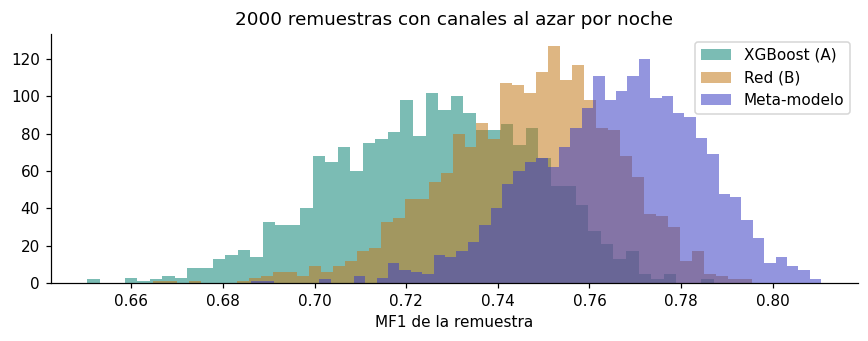

In [8]:
# Distribución del MF1 en las 2000 remuestras
fig, ax = plt.subplots(figsize=(8, 3.2))
for name, color in [("XGBoost (A)", "#0f8577"), ("Red (B)", "#c47a1b"), ("Meta-modelo", "#3b3fc4")]:
    ax.hist(boot_mix[name].mf1, bins=50, alpha=0.55, color=color, label=name)
ax.set_xlabel("MF1 de la remuestra")
ax.set_title("2000 remuestras con canales al azar por noche")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Confianza

### La confianza de una época

Es la probabilidad más alta que da el meta-modelo. Ejemplo con las primeras épocas de una noche de la CV, solo con Fpz-Cz:

In [9]:
# Probabilidades, estadio elegido y confianza de unas épocas
n = sorted(META["oof"]["fpz"])[0]
y, p = META["oof"]["fpz"][n]
i = np.arange(60, 70)
ejemplo = pd.DataFrame(p[i].round(2), columns=ESTADIOS, index=pd.Index(i, name="época"))
ejemplo["estadio"] = [ESTADIOS[k] for k in p[i].argmax(1)]
ejemplo["confianza"] = p[i].max(1).round(2)
ejemplo["real"] = [ESTADIOS[k] if k >= 0 else "?" for k in y[i]]
ejemplo

,W,N1,N2,N3,REM,estadio,confianza,real
época,,,,,,,,
60,0.18,0.75,0.03,0.0,0.04,N1,0.75,N1
61,0.14,0.78,0.03,0.0,0.05,N1,0.78,N1
62,0.10,0.80,0.04,0.0,0.06,N1,0.80,N1
63,0.09,0.80,0.04,0.0,0.07,N1,0.80,N1
64,0.09,0.77,0.05,0.0,0.09,N1,0.77,N1
65,0.06,0.71,0.07,0.0,0.15,N1,0.71,N1
66,0.06,0.60,0.11,0.0,0.22,N1,0.60,N1
67,0.04,0.37,0.18,0.0,0.41,REM,0.41,N1
68,0.03,0.25,0.23,0.0,0.49,REM,0.49,N1


### Elegir el umbral con la CV

Para cada umbral se mide, con las 12 combinaciones juntas:
- **entrega:** qué parte de la noche entrega el sistema solo (confianza ≥ umbral);
- **acierto ahí** y **MF1 ahí:** en esa parte;
- **acierto en revisar:** en lo que queda para revisar, si se tomara la 1.ª opción;
- **2 opciones en revisar:** qué tan seguido la correcta está entre la 1.ª y la 2.ª opción.

In [10]:
# Funciones para resumir una noche con un umbral
def _f1_macro(cm):
    tp, rows, cols = np.diag(cm), cm.sum(1), cm.sum(0)
    return np.divide(2 * tp, rows + cols, out=np.zeros(K), where=(rows + cols) > 0).mean()


def night_stats(y, p, umbral):
    v = y >= 0
    y, p = y[v], p[v]
    o = np.argsort(-p, 1)
    conf, t1, t2 = p.max(1), o[:, 0], o[:, 1]
    seg, ok, top2 = conf >= umbral, t1 == y, (t1 == y) | (t2 == y)
    cm = np.bincount(y[seg] * K + t1[seg], minlength=K * K).reshape(K, K)
    return {"n": len(y), "seg": seg.sum(), "ok_seg": (ok & seg).sum(), "dud": (~seg).sum(), "ok_dud": (ok & ~seg).sum(),
            "top2_dud": (top2 & ~seg).sum(), "ok": ok.sum(), "combinado": (ok & seg).sum() + (top2 & ~seg).sum(), "cm_seg": cm}


def summarize(stats):
    t = {k: sum(s[k] for s in stats) for k in stats[0]}
    return {"entrega": t["seg"] / t["n"], "acierto ahí": t["ok_seg"] / t["seg"], "MF1 ahí": _f1_macro(t["cm_seg"]),
            "acierto en revisar": t["ok_dud"] / max(t["dud"], 1), "2 opciones en revisar": t["top2_dud"] / max(t["dud"], 1),
            "acierto sin revisión": t["ok"] / t["n"], "acierto con revisión": t["combinado"] / t["n"]}

In [11]:
# Curva de la CV y umbral elegido
noches_cv = [(c, n) for c in CONFIGS for n in META["oof"][c]]
curva = pd.DataFrame([{"umbral": u, **summarize([night_stats(*META["oof"][c][n], u) for c, n in noches_cv])}
                      for u in UMBRALES]).set_index("umbral")
umbral = float(curva.index[curva["acierto ahí"] >= ACIERTO_MINIMO][0])
print(f"umbral elegido con la CV: {umbral}")
curva.iloc[:, :5].style.format(precision=3)

umbral elegido con la CV: 0.65


,entrega,acierto ahí,MF1 ahí,acierto en revisar,2 opciones en revisar
umbral,,,,,
0.500000,0.957,0.862,0.814,0.449,0.823
0.550000,0.912,0.878,0.828,0.487,0.876
0.600000,0.868,0.894,0.842,0.515,0.894
0.650000,0.823,0.909,0.856,0.540,0.905
0.700000,0.777,0.923,0.868,0.567,0.912
0.750000,0.727,0.937,0.879,0.595,0.919
0.800000,0.671,0.951,0.888,0.626,0.925
0.850000,0.607,0.964,0.892,0.658,0.931
0.900000,0.530,0.976,0.883,0.694,0.937


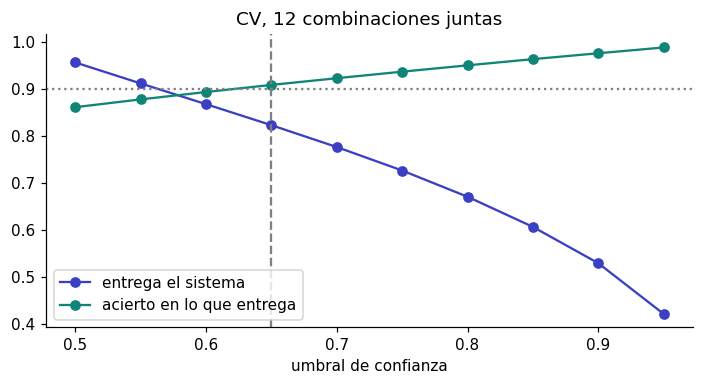

In [12]:
# Lo que entrega el sistema frente a su acierto, según el umbral
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(curva.index, curva["entrega"], "o-", color="#3b3fc4", label="entrega el sistema")
ax.plot(curva.index, curva["acierto ahí"], "o-", color="#0f8577", label="acierto en lo que entrega")
ax.axhline(ACIERTO_MINIMO, ls=":", color="gray")
ax.axvline(umbral, ls="--", color="gray")
ax.set_xlabel("umbral de confianza")
ax.set_title("CV, 12 combinaciones juntas")
ax.legend()
plt.tight_layout()
plt.show()

### Aviso por noche

Con el umbral elegido, calculamos qué fracción de cada noche de la CV queda para revisar. El percentil 90 es el límite del aviso: si una noche lo supera, conviene revisarla completa.

aviso por noche si se revisa más del 27.7%


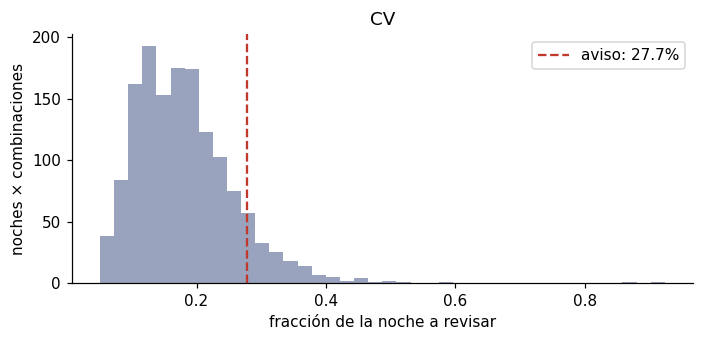

In [13]:
# Fracción a revisar por noche en la CV y límite del aviso
frac_cv = np.array([s["dud"] / s["n"] for s in (night_stats(*META["oof"][c][n], umbral) for c, n in noches_cv)])
aviso = float(np.quantile(frac_cv, PERCENTIL_AVISO))
print(f"aviso por noche si se revisa más del {aviso:.1%}")

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.hist(frac_cv, bins=40, color="#9aa3bd")
ax.axvline(aviso, ls="--", color="#c0392b", label=f"aviso: {aviso:.1%}")
ax.set_xlabel("fracción de la noche a revisar")
ax.set_ylabel("noches × combinaciones")
ax.set_title("CV")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Calibración

Cuando el sistema dice 80 %, ¿acierta el 80 %? Se agrupan las épocas por tramos de confianza y se compara la confianza media con el acierto real. El **ECE** es la diferencia media, ponderada por la cantidad de épocas de cada tramo.

In [14]:
# Función para la curva de calibración y el ECE
TRAMOS = np.linspace(0, 1, 11)


def calibration(preds):
    y = np.concatenate([v[0] for v in preds.values()])
    p = np.concatenate([v[1] for v in preds.values()])
    v = y >= 0
    y, p = y[v], p[v]
    conf, ok = p.max(1), p.argmax(1) == y
    idx = np.clip(np.digitize(conf, TRAMOS) - 1, 0, len(TRAMOS) - 2)
    t = pd.DataFrame([{"conf": conf[idx == b].mean(), "acierto": ok[idx == b].mean(), "fraccion": (idx == b).mean()}
                      for b in np.unique(idx)])
    return t, (abs(t.acierto - t.conf) * t.fraccion).sum()

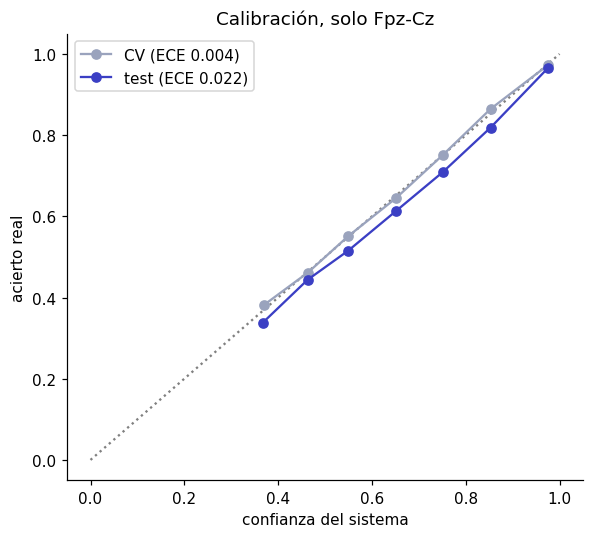

In [15]:
# Calibración en la CV y en el test, solo con Fpz-Cz
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], ls=":", color="gray")
for nombre, preds, color in [("CV", META["oof"]["fpz"], "#9aa3bd"), ("test", META["test"]["fpz"], "#3b3fc4")]:
    t, ece = calibration(preds)
    t = t[t.fraccion >= 0.005]
    ax.plot(t.conf, t.acierto, "o-", color=color, label=f"{nombre} (ECE {ece:.3f})")
ax.set_xlabel("confianza del sistema")
ax.set_ylabel("acierto real")
ax.set_title("Calibración, solo Fpz-Cz")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Test con el umbral

Se aplica el umbral elegido a los 16 sujetos de test, una sola vez. Entre corchetes, el IC 95 % por bootstrap por sujeto. La última fila usa la misma combinación al azar por noche de la sección 4.

In [16]:
# Resultados del test con el umbral, por combinación y con canales al azar
COLS = ["entrega", "acierto ahí", "MF1 ahí", "2 opciones en revisar", "acierto sin revisión", "acierto con revisión"]
noches_de = {s: [n for n in NOCHES_TEST if int(n[3:5]) == s] for s in SUJETOS_TEST}
rng = np.random.default_rng(SEED)
sorteos = [rng.choice(SUJETOS_TEST, size=len(SUJETOS_TEST), replace=True) for _ in range(N_BOOT)]


def ic(b, col):
    return f"[{b[col].quantile(0.025):.3f}, {b[col].quantile(0.975):.3f}]"


filas = []
for c in CONFIGS:
    st = {n: night_stats(*META["test"][c][n], umbral) for n in NOCHES_TEST}
    b = pd.DataFrame([summarize([st[n] for s in d for n in noches_de[s]]) for d in sorteos])
    filas.append({"combinación": c, **summarize(list(st.values())),
                  "IC entrega": ic(b, "entrega"), "IC acierto ahí": ic(b, "acierto ahí")})

st_all = {(n, c): night_stats(*META["test"][c][n], umbral) for n in NOCHES_TEST for c in CONFIGS}
rng_mix = np.random.default_rng(SEED)
b = []
for _ in range(N_BOOT):
    idx = [n for s in rng_mix.choice(SUJETOS_TEST, size=len(SUJETOS_TEST), replace=True) for n in noches_de[s]]
    pick = rng_mix.integers(0, len(CONFIGS), size=len(idx))
    b.append(summarize([st_all[(n, CONFIGS[k])] for n, k in zip(idx, pick)]))
b = pd.DataFrame(b)
filas.append({"combinación": "al azar por noche", **summarize(list(st_all.values())),
              "IC entrega": ic(b, "entrega"), "IC acierto ahí": ic(b, "acierto ahí")})
tabla_test = pd.DataFrame(filas).set_index("combinación")
tabla_test[COLS + ["IC entrega", "IC acierto ahí"]].style.format(precision=3)

,entrega,acierto ahí,MF1 ahí,2 opciones en revisar,acierto sin revisión,acierto con revisión,IC entrega,IC acierto ahí
combinación,,,,,,,,
fpz,0.799,0.888,0.831,0.853,0.811,0.881,"[0.765, 0.829]","[0.866, 0.907]"
pz,0.783,0.847,0.795,0.878,0.778,0.854,"[0.754, 0.811]","[0.771, 0.897]"
eeg2,0.812,0.889,0.839,0.858,0.818,0.884,"[0.775, 0.842]","[0.868, 0.908]"
fpz_eog,0.805,0.890,0.841,0.859,0.814,0.883,"[0.778, 0.829]","[0.870, 0.908]"
pz_eog,0.791,0.864,0.815,0.851,0.788,0.861,"[0.768, 0.813]","[0.807, 0.902]"
eeg2_eog,0.822,0.888,0.842,0.869,0.819,0.885,"[0.788, 0.848]","[0.867, 0.908]"
fpz_emg,0.797,0.888,0.835,0.851,0.809,0.880,"[0.762, 0.828]","[0.867, 0.906]"
pz_emg,0.785,0.847,0.797,0.878,0.777,0.853,"[0.753, 0.817]","[0.770, 0.895]"
eeg2_emg,0.818,0.886,0.837,0.866,0.816,0.882,"[0.786, 0.847]","[0.864, 0.906]"


Noches del test que superan el límite del aviso, y su acierto frente al de las demás:

In [17]:
# Noches con aviso en el test
por_noche = pd.DataFrame([{"combinación": c, "noche": n, "fracción a revisar": s["dud"] / s["n"], "acierto": s["ok"] / s["n"]}
                          for (n, c), s in st_all.items()])
alerta = por_noche["fracción a revisar"] > aviso
print(f"noches con aviso: {alerta.sum()} de {len(por_noche)} (noche × combinación)")
print(f"acierto medio: {por_noche.acierto[alerta].mean():.3f} con aviso, {por_noche.acierto[~alerta].mean():.3f} sin aviso")

noches con aviso: 56 de 384 (noche × combinación)
acierto medio: 0.732 con aviso, 0.815 sin aviso


## 8. Así entrega el sistema una noche

Para cada época: el estadio, la confianza, la 2.ª opción y si hay que revisarla. Primera noche de test, solo con Fpz-Cz; se muestran las primeras épocas marcadas para revisar.

In [18]:
# Salida del sistema época por época
noche = NOCHES_TEST[0]
y, p = META["test"]["fpz"][noche]
o = np.argsort(-p, 1)
i = np.arange(len(p))
salida = pd.DataFrame({"estadio": np.array(ESTADIOS)[o[:, 0]], "confianza": p[i, o[:, 0]].round(3),
                       "2.ª opción": np.array(ESTADIOS)[o[:, 1]], "prob. 2.ª": p[i, o[:, 1]].round(3),
                       "revisar": p[i, o[:, 0]] < umbral, "real": ["?" if v < 0 else ESTADIOS[v] for v in y]},
                      index=pd.Index(i, name="época"))
print(f"{noche}: {salida.revisar.mean():.1%} de la noche a revisar · aviso: {'sí' if salida.revisar.mean() > aviso else 'no'}")
salida[salida.revisar].head(10)

SC4001: 12.6% de la noche a revisar · aviso: no


,estadio,confianza,2.ª opción,prob. 2.ª,revisar,real
época,,,,,,
59,N1,0.523,W,0.472,True,W
64,N1,0.571,N2,0.408,True,N2
65,N2,0.575,N1,0.411,True,N2
79,N2,0.617,N3,0.376,True,N3
99,N1,0.523,N2,0.254,True,W
100,N3,0.485,N2,0.348,True,N3
101,N3,0.544,N2,0.412,True,N3
103,N3,0.557,N2,0.424,True,N2
104,N3,0.616,N2,0.375,True,N3


## 9. Guardar en `sistema.json`

Se agregan el umbral y el límite del aviso a la descripción del sistema.

In [19]:
# Umbral y aviso en sistema.json
sistema = json.loads(SISTEMA.read_text())
sistema["umbral_confianza"] = umbral
sistema["aviso_noche_fraccion_revisar"] = round(aviso, 4)
SISTEMA.write_text(json.dumps(sistema, indent=2, ensure_ascii=False) + "\n")
print(f"guardado en {SISTEMA.relative_to(RAIZ)}: umbral {umbral}, aviso {aviso:.4f}")

guardado en modelo/sistema.json: umbral 0.65, aviso 0.2774


## 10. Conclusiones

- Con una combinación de canales al azar por noche, el sistema da MF1 0.767 y κ 0.738 (con el XGBoost de 719, 0.768 y 0.740), y supera de forma significativa a A y a B por separado.
- Con el umbral de 0.65, elegido con la CV, el sistema entrega ~80 % de la noche con ~88 % de acierto, y deja el resto para revisión con dos opciones.
- En lo que queda para revisar, la correcta está entre las dos opciones el 86 % de las veces: con la revisión, el acierto de la noche sube de 0.80 a 0.87.
- Las noches que disparan el aviso (más del 27.7 % a revisar) aciertan bastante menos, 0.732 frente a 0.815, así que el aviso sirve.
- El sistema está bien calibrado en la CV (ECE 0.004) y algo sobreconfiado en el test (ECE 0.022).